In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_excel(r"C:\Users\hp 745 g6\OneDrive\Desktop\Infosys\Supply_Chain_Raw_Dataset.xlsx")

In [7]:
df.head()

,Order ID,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Segment,Department Name,...,Sales,Unit Price,Order Item Total,Order Profit Per Order,Order Region,Order Status,Product Name,shipping date,Shipping Mode,Inventory Stock (Units)
0,ORD100001,CASH,3.0,1.0,Late delivery,1.0,Books,Dallas,Home Office,Sports,...,3521.07,704.214000,3504.60,104.58,Central,CLOSED,Keyboard,05/07/2023,Second Class,2885.0
1,ORD100002,DEBIT,6.0,6.0,Advance shipping,0.0,Electronics,Phoenix,Corporate,Fashion,...,1506.54,502.180000,1483.86,218.45,South,CLOSED,Desk,01/30/2023,Standard Class,5232.0
2,ORD100003,CASH,6.0,6.0,Advance shipping,0.0,Sports,Los Angeles,Corporate,Fashion,...,890.72,148.453333,889.25,-17.61,South,SUSPECTED_FRAUD,Keyboard,10/14/2023,Second Class,2885.0
3,ORD100004,CASH,8.0,6.0,Late delivery,1.0,Office Supplies,Dallas,Consumer,Technology,...,1267.53,181.075714,1226.66,18.87,South,CLOSED,Printer,02/01/2024,Standard Class,4373.0
4,ORD100005,PAYMENT,2.0,1.0,Late delivery,1.0,Furniture,Houston,Corporate,Home,...,3662.80,457.850000,3629.32,-7.60,North,PENDING,Keyboard,12/19/2023,First Class,2885.0


In [8]:
df.tail()

,Order ID,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Segment,Department Name,...,Sales,Unit Price,Order Item Total,Order Profit Per Order,Order Region,Order Status,Product Name,shipping date,Shipping Mode,Inventory Stock (Units)
2594,ORD102595,PAYMENT,3.0,3.0,Advance shipping,0.0,Health,Denver,Corporate,Books,...,671.65,671.650000,642.60,22.88,South,PENDING,Keyboard,09/03/2023,First Class,2885.0
2595,ORD102596,CASH,1.0,2.0,Shipping on time,0.0,Office Supplies,Denver,Corporate,Furniture,...,2280.34,760.113333,2247.61,158.83,West,SUSPECTED_FRAUD,Headphones,07/01/2024,Same Day,4720.0
2596,ORD102597,PAYMENT,6.0,4.0,Late delivery,1.0,Health,Denver,Corporate,Office,...,5564.15,618.238889,5546.67,77.01,North,COMPLETE,Backpack,01/26/2025,First Class,4567.0
2597,ORD102598,DEBIT,1.0,1.0,Advance shipping,0.0,Home,Boston,Consumer,Fashion,...,3802.75,633.791667,3769.84,82.41,Central,PENDING,Office Chair,10/11/2024,Standard Class,4256.0
2598,ORD102599,DEBIT,3.0,3.0,Shipping on time,0.0,Health,Miami,Home Office,Furniture,...,368.11,92.027500,359.48,194.18,Central,CLOSED,Office Chair,11/19/2024,Same Day,4256.0


In [9]:
df.shape

(2599, 24)

In [10]:
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,Order Item Quantity,Sales,Unit Price,Order Item Total,Order Profit Per Order,Inventory Stock (Units)
count,2593.000000,2587.000000,2590.000000,2599.000000,2599.000000,2599.000000,2589.000000,2592.000000,2593.000000
mean,3.953336,3.502126,0.415058,5.565987,2358.664979,420.785537,2334.813345,84.697296,4061.080216
std,1.921226,1.715759,0.492827,2.808929,1919.598529,235.395781,1920.615796,95.449517,1094.786629
min,1.000000,1.000000,0.000000,1.000000,15.460000,14.075000,-22.450000,-97.210000,1790.000000
25%,2.000000,2.000000,0.000000,3.000000,724.045000,212.280417,702.980000,-0.390000,3160.000000
50%,4.000000,4.000000,0.000000,6.000000,1879.240000,422.975000,1854.580000,85.195000,4373.000000
75%,5.000000,5.000000,1.000000,8.000000,3519.000000,624.902000,3502.020000,165.867500,4720.000000
max,8.000000,6.000000,1.000000,10.000000,8989.580000,912.985000,8969.500000,266.750000,5609.000000


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2599 entries, 0 to 2598
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Order ID                       2599 non-null   str    
 1   Type                           2593 non-null   str    
 2   Days for shipping (real)       2593 non-null   float64
 3   Days for shipment (scheduled)  2587 non-null   float64
 4   Delivery Status                2592 non-null   str    
 5   Late_delivery_risk             2590 non-null   float64
 6   Category Name                  2588 non-null   str    
 7   Customer City                  2589 non-null   str    
 8   Customer Segment               2590 non-null   str    
 9   Department Name                2584 non-null   str    
 10  Market                         2592 non-null   str    
 11  Order Country                  2592 non-null   str    
 12  order date                     2599 non-null   str    
 13 

In [12]:
df.columns = df.columns.str.strip()

In [13]:
df["order date"]= pd.to_datetime(df["order date"])
df["shipping date"]= pd.to_datetime(df["shipping date"])

In [14]:
df.rename(columns={'Late_delivery_risk': 'Late delivery risk'}, inplace=True)
df.rename(columns={'order date': 'Order date'}, inplace=True)
df.rename(columns={'shipping date': 'Shipping date'}, inplace=True)

In [15]:
df.isnull().sum()    

Order ID                          0
Type                              6
Days for shipping (real)          6
Days for shipment (scheduled)    12
Delivery Status                   7
Late delivery risk                9
Category Name                    11
Customer City                    10
Customer Segment                  9
Department Name                  15
Market                            7
Order Country                     7
Order date                        0
Order Item Quantity               0
Sales                             0
Unit Price                        0
Order Item Total                 10
Order Profit Per Order            7
Order Region                     12
Order Status                      3
Product Name                      6
Shipping date                     0
Shipping Mode                     3
Inventory Stock (Units)           6
dtype: int64

In [16]:
numerical_cols = df.select_dtypes(include='number').columns

print(numerical_cols)

Index(['Days for shipping (real)', 'Days for shipment (scheduled)',
       'Late delivery risk', 'Order Item Quantity', 'Sales', 'Unit Price',
       'Order Item Total', 'Order Profit Per Order',
       'Inventory Stock (Units)'],
      dtype='str')


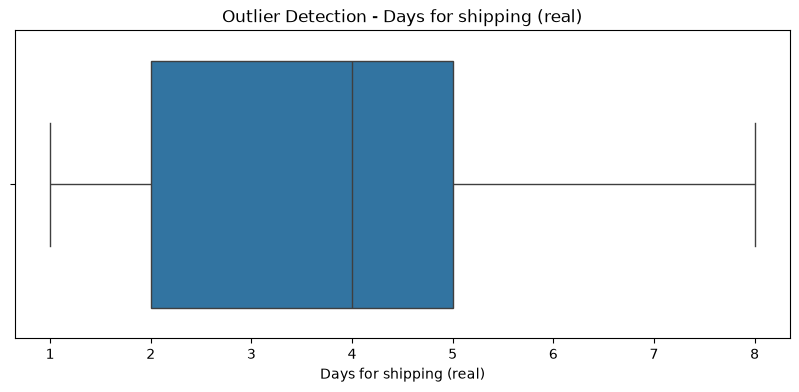

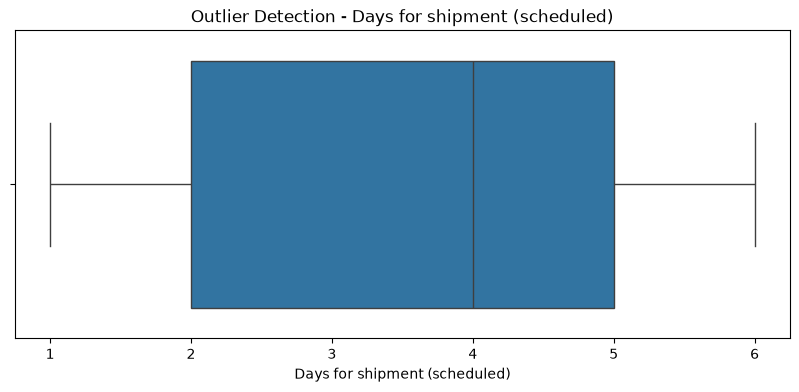

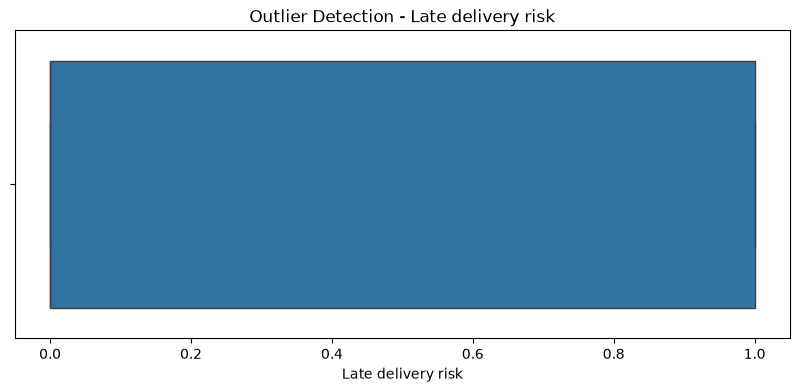

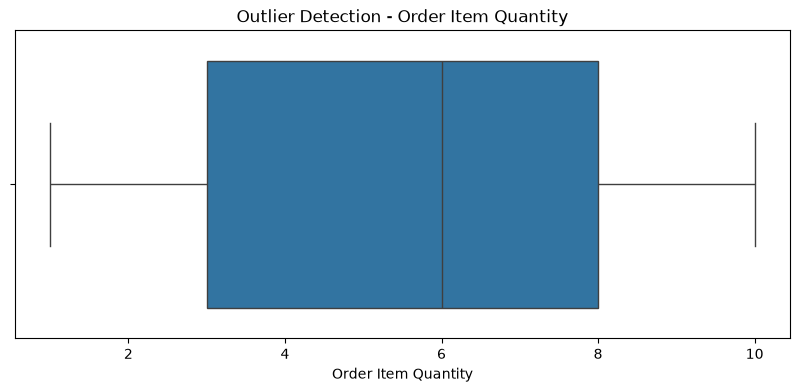

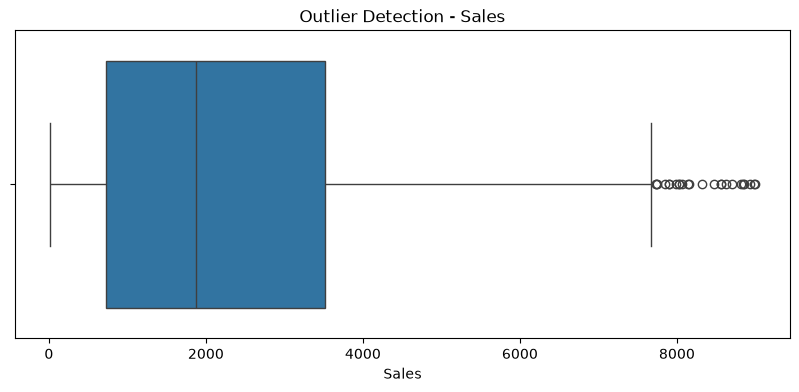

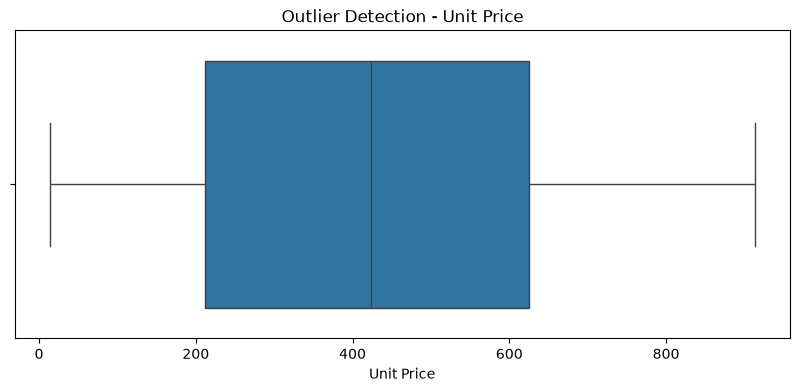

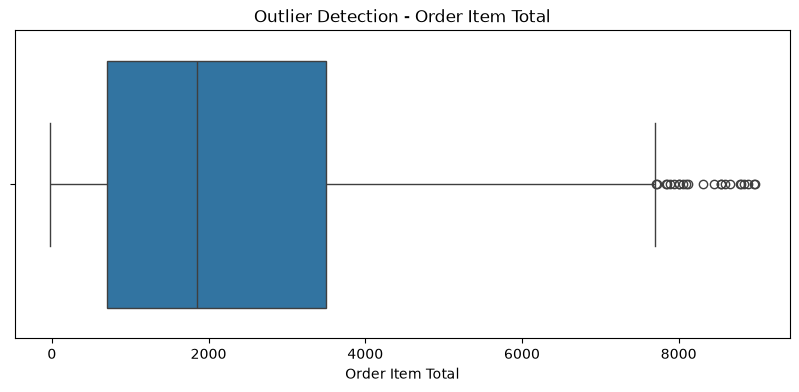

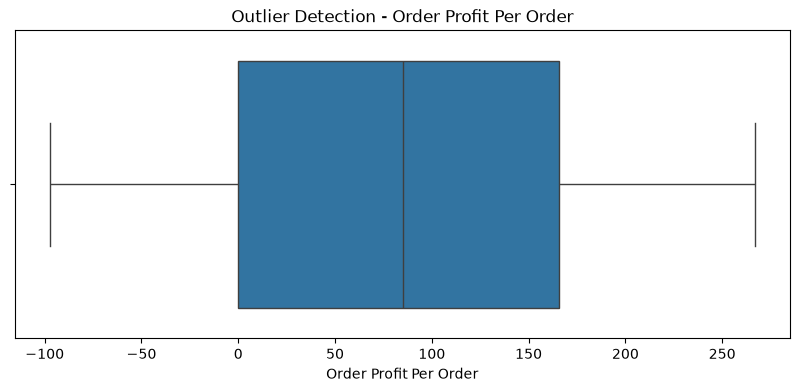

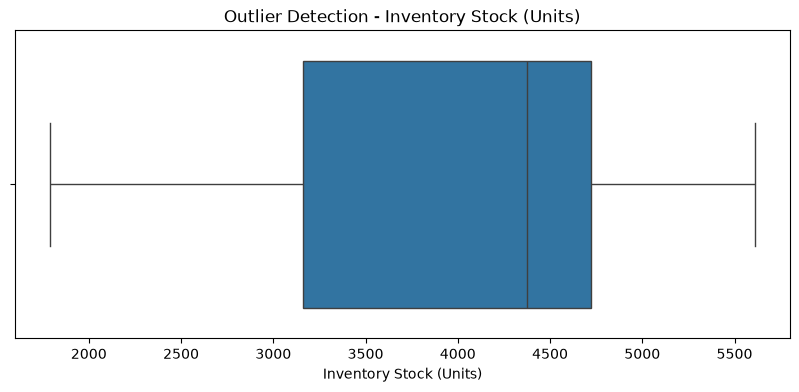

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = df.select_dtypes(include='number').columns

for col in numerical_cols:
    plt.figure(figsize=(10, 4))
    
    sns.boxplot(x=df[col])
    
    plt.title(f'Outlier Detection - {col}')
    plt.xlabel(col)
    plt.show()

In [18]:
categorical_cols = [
    "Order ID",
    "Type",
    "Delivery Status",
    "Category Name",
    "Customer City",
    "Customer Segment",
    "Department Name",
    "Market",
    "Order Country",
    "Order Region",
    "Order Status",
    "Product Name",
    "Shipping Mode"
]

# Display only categorical columns
df[categorical_cols].head()

,Order ID,Type,Delivery Status,Category Name,Customer City,Customer Segment,Department Name,Market,Order Country,Order Region,Order Status,Product Name,Shipping Mode
0,ORD100001,CASH,Late delivery,Books,Dallas,Home Office,Sports,LATAM,France,Central,CLOSED,Keyboard,Second Class
1,ORD100002,DEBIT,Advance shipping,Electronics,Phoenix,Corporate,Fashion,USCA,India,South,CLOSED,Desk,Standard Class
2,ORD100003,CASH,Advance shipping,Sports,Los Angeles,Corporate,Fashion,Pacific Asia,Brazil,South,SUSPECTED_FRAUD,Keyboard,Second Class
3,ORD100004,CASH,Late delivery,Office Supplies,Dallas,Consumer,Technology,Pacific Asia,Australia,South,CLOSED,Printer,Standard Class
4,ORD100005,PAYMENT,Late delivery,Furniture,Houston,Corporate,Home,Pacific Asia,Brazil,North,PENDING,Keyboard,First Class


In [24]:
# Fill numerical columns with outliers using Median
df["Sales"] = df["Sales"].fillna(df["Sales"].median())
df["Order Item Total"] = df["Order Item Total"].fillna(df["Order Item Total"].median())


# Fill numerical columns without outliers using Mean
df["Unit Price"] = df["Unit Price"].fillna(df["Unit Price"].mean())
df["Order Item Quantity"] = df["Order Item Quantity"].fillna(df["Order Item Quantity"].mean())
df["Days for shipping (real)"] = df["Days for shipping (real)"].fillna(df["Days for shipping (real)"].mean())
df["Days for shipment (scheduled)"] = df["Days for shipment (scheduled)"].fillna(df["Days for shipment (scheduled)"].mean())
df["Late delivery risk"] = df["Late delivery risk"].fillna(df["Late delivery risk"].mean())
df["Order Profit Per Order"] = df["Order Profit Per Order"].fillna(df["Order Profit Per Order"].mean())
df["Inventory Stock (Units)"] = df["Inventory Stock (Units)"].fillna(df["Inventory Stock (Units)"].mean())


# Fill categorical columns using Mode
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

C:\Users\hp 745 g6\AppData\Local\Temp\ipykernel_10940\2126870717.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [20]:
df.isnull().sum()   

Order ID                         0
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Delivery Status                  0
Late delivery risk               0
Category Name                    0
Customer City                    0
Customer Segment                 0
Department Name                  0
Market                           0
Order Country                    0
Order date                       0
Order Item Quantity              0
Sales                            0
Unit Price                       0
Order Item Total                 0
Order Profit Per Order           0
Order Region                     0
Order Status                     0
Product Name                     0
Shipping date                    0
Shipping Mode                    0
Inventory Stock (Units)          0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.to_excel("Cleaned dataset.xlsx", index=False)